In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
df = pd.read_csv("arac_fiyat_tahmini.csv")

In [16]:
df

,marka,model_yili,kilometre,motor_hacmi_cc,yakit_turu,vites,beygir_gucu,hasar_kaydi_adedi,bakim_gecmisi,kasa_tipi,fiyat_tl
0,Hyundai,2023,27775.0,1800,Elektrik,Otomatik,125.0,0.0,Yok,Hatchback,1205187.0
1,Renault,2011,164400.0,1400,Benzin,Otomatik,96.0,2.0,Yok,SUV,346060.0
2,Toyota,2019,93560.0,1800,Elektrik,Otomatik,139.0,0.0,Yok,Hatchback,984269.0
3,Ford,2012,155095.0,2000,Dizel,Manuel,153.0,1.0,Yok,Hatchback,408760.0
4,Fiat,2018,129024.0,1800,Elektrik,Manuel,NaN,0.0,Yok,Hatchback,939370.0
...,...,...,...,...,...,...,...,...,...,...,...
795,Hyundai,2022,46175.0,1800,Dizel,Otomatik,126.0,0.0,Tam,Station Wagon,1013429.0
796,Volkswagen,2013,136309.0,1200,LPG,Otomatik,91.0,0.0,Kısmi,Sedan,641191.0
797,Ford,2012,126707.0,1200,Hibrit,Manuel,106.0,0.0,Yok,SUV,509171.0
798,Ford,2023,72745.0,1000,Hibrit,Manuel,NaN,1.0,Tam,Station Wagon,950085.0


In [17]:
df.head(5)

,marka,model_yili,kilometre,motor_hacmi_cc,yakit_turu,vites,beygir_gucu,hasar_kaydi_adedi,bakim_gecmisi,kasa_tipi,fiyat_tl
0,Hyundai,2023,27775.0,1800,Elektrik,Otomatik,125.0,0.0,Yok,Hatchback,1205187.0
1,Renault,2011,164400.0,1400,Benzin,Otomatik,96.0,2.0,Yok,SUV,346060.0
2,Toyota,2019,93560.0,1800,Elektrik,Otomatik,139.0,0.0,Yok,Hatchback,984269.0
3,Ford,2012,155095.0,2000,Dizel,Manuel,153.0,1.0,Yok,Hatchback,408760.0
4,Fiat,2018,129024.0,1800,Elektrik,Manuel,NaN,0.0,Yok,Hatchback,939370.0


In [18]:
df.shape

(800, 11)

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   marka              800 non-null    object 
 1   model_yili         800 non-null    int64  
 2   kilometre          800 non-null    float64
 3   motor_hacmi_cc     800 non-null    int64  
 4   yakit_turu         800 non-null    object 
 5   vites              800 non-null    object 
 6   beygir_gucu        780 non-null    float64
 7   hasar_kaydi_adedi  784 non-null    float64
 8   bakim_gecmisi      788 non-null    object 
 9   kasa_tipi          800 non-null    object 
 10  fiyat_tl           800 non-null    float64
dtypes: float64(4), int64(2), object(5)
memory usage: 68.9+ KB


In [22]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
model_yili,800.0,2016.757500,5.236456,2008.0,2012.00,2017.0,2021.00,2025.0
kilometre,800.0,105086.068750,64569.113154,500.0,49985.25,104197.5,155817.50,249327.0
motor_hacmi_cc,800.0,1494.250000,338.984625,1000.0,1200.00,1400.0,1800.00,2000.0
beygir_gucu,780.0,127.160256,33.986801,65.0,100.00,124.0,152.00,209.0
hasar_kaydi_adedi,784.0,0.706633,0.988132,0.0,0.00,0.0,1.00,4.0
fiyat_tl,800.0,766689.631250,316995.119960,180000.0,515482.75,759958.0,992646.75,1550677.0


In [23]:
df.isnull().sum()

marka                 0
model_yili            0
kilometre             0
motor_hacmi_cc        0
yakit_turu            0
vites                 0
beygir_gucu          20
hasar_kaydi_adedi    16
bakim_gecmisi        12
kasa_tipi             0
fiyat_tl              0
dtype: int64

In [24]:
print(
    "Tekrarlanan satır sayısı:",
    df.duplicated().sum()
)

Tekrarlanan satır sayısı: 0


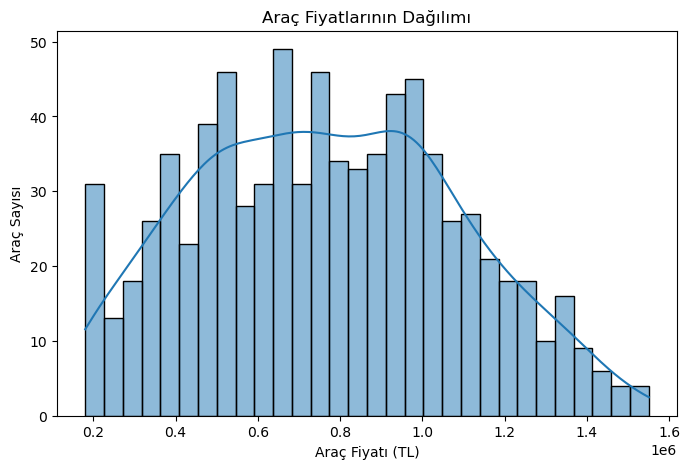

In [25]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["fiyat_tl"],
    bins=30,
    kde=True
)

plt.title("Araç Fiyatlarının Dağılımı")
plt.xlabel("Araç Fiyatı (TL)")
plt.ylabel("Araç Sayısı")

plt.show()

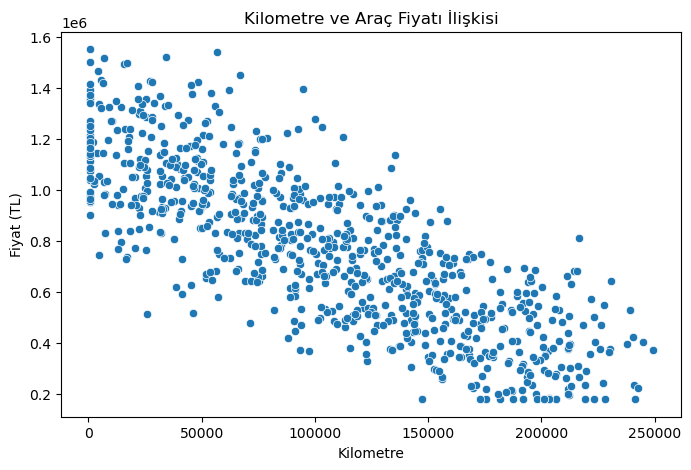

In [26]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="kilometre",
    y="fiyat_tl"
)

plt.title("Kilometre ve Araç Fiyatı İlişkisi")
plt.xlabel("Kilometre")
plt.ylabel("Fiyat (TL)")

plt.show()

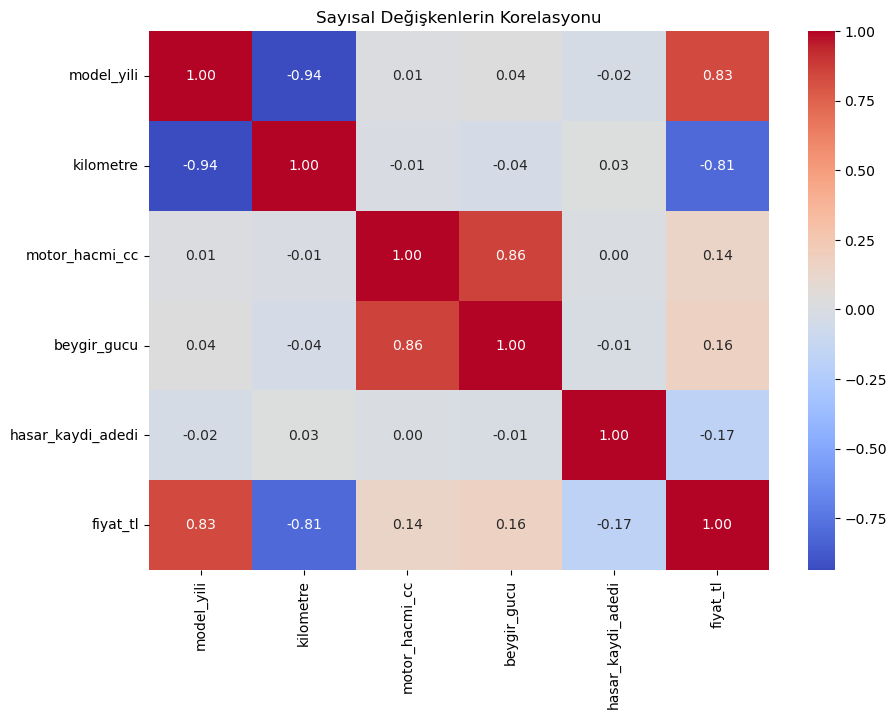

In [27]:
numeric_df = df.select_dtypes(
    include="number"
)

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Sayısal Değişkenlerin Korelasyonu")

plt.show()